# Taller práctico: EDA con Python
## Ingeniería de Datos e Inteligencia Artificial

**Duración sugerida:** 3 horas. **Nivel:** fundamentos de Python.  
**Bibliotecas:** pandas, NumPy, Matplotlib, Seaborn y scikit-learn.

### Objetivo
Construir un proceso guiado de Análisis Exploratorio de Datos (EDA): inspección, diagnóstico de calidad, limpieza, análisis estadístico, visualización, detección de valores atípicos, normalización y estandarización.

### Resultados de aprendizaje
1. Inspeccionar estructura, tipos y calidad de un dataset.
2. Detectar faltantes, duplicados, inconsistencias y valores fuera de rango.
3. Justificar las decisiones de limpieza y conservar trazabilidad.
4. Interpretar gráficos univariados y bivariados.
5. Diferenciar normalización Min-Max y estandarización Z-score.
6. Reconocer riesgos de fuga de información al preparar datos para IA.

**Caso:** una organización analiza transacciones comerciales sintéticas. No hay datos personales reales. Las reglas y rangos son didácticos y deben validarse con el negocio en un proyecto real.

**Flujo:** entender → inspeccionar → perfilar calidad → limpiar → analizar → visualizar → transformar → comunicar hallazgos.

## 1. Preparar el entorno

Instala las bibliotecas si el entorno no las tiene:
```bash
python -m pip install pandas numpy matplotlib seaborn scikit-learn jupyter
```

In [4]:
%pip install pandas numpy matplotlib seaborn scikit-learn

  Using cached pandas-3.0.6-cp315-cp315-win_amd64.whl.metadata (19 kB)
  Using cached numpy-2.5.4-cp315-cp315-win_amd64.whl.metadata (6.6 kB)
  Using cached matplotlib-3.11.2-cp315-cp315-win_amd64.whl.metadata (80 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached scikit_learn-1.9.1-cp315-cp315-win_amd64.whl.metadata (9.3 kB)
  Using cached tzdata-2026.5-py2.py3-none-any.whl.metadata (1.4 kB)
  Using cached contourpy-1.4.0-cp315-cp315-win_amd64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.67.0-cp315-cp315-win_amd64.whl.metadata (139 kB)
  Using cached kiwisolver-1.5.1-cp315-cp315-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp315-cp315-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached scipy-1.18.1-cp315-cp315-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 2. Cargar los datos

Descarga `transacciones_eda_taller.csv` y guárdalo en la misma carpeta del notebook.
Cada fila representa una transacción. Las columnas incluyen fecha, edad, ciudad, canal, categoría, cantidad, monto, descuento y satisfacción. El archivo contiene problemas intencionales para practicar EDA.

In [8]:
df = pd.read_csv("transacciones_eda_taller.csv", encoding="latin1")
df.head()

,id_transaccion,fecha,edad_cliente,ciudad,canal,categoria,cantidad,monto_compra,descuento,satisfaccion
0,T0001,01/01/2025,40.0,Cali,App,tecnología,3,50750.74,0.25,4.4
1,T0002,02/01/2025,26.0,Medellín,WEB,Tecnología,2,21911.37,0.00,4.3
2,T0003,03/01/2025,45.0,Bogotá,WEB,Ropa,3,52685.83,0.15,2.6
3,T0004,04/01/2025,47.0,bogotá,app,Alimentos,1,19084.00,0.10,3.9
4,T0005,05/01/2025,NaN,Cali,app,tecnología,5,54191.27,0.20,4.8


## 3. Inspección inicial

Antes de limpiar, registra el estado original. No modifiques la fuente sin conservar una copia.

In [10]:
print("Dimensiones:", df.shape)
display(df.head(10))
df.info()
display(df.describe(include="all").T)

Dimensiones: (181, 10)


,id_transaccion,fecha,edad_cliente,ciudad,canal,categoria,cantidad,monto_compra,descuento,satisfaccion
0,T0001,01/01/2025,40.0,Cali,App,tecnología,3,50750.74,0.25,4.4
1,T0002,02/01/2025,26.0,Medellín,WEB,Tecnología,2,21911.37,0.00,4.3
2,T0003,03/01/2025,45.0,Bogotá,WEB,Ropa,3,52685.83,0.15,2.6
3,T0004,04/01/2025,47.0,bogotá,app,Alimentos,1,19084.00,0.10,3.9
4,T0005,05/01/2025,NaN,Cali,app,tecnología,5,54191.27,0.20,4.8
5,T0006,06/01/2025,23.0,Barranquilla,App,Ropa,2,26168.64,0.00,4.8
6,T0007,07/01/2025,38.0,Cali,app,HOGAR,3,28057.91,0.25,4.8
7,T0008,08/01/2025,34.0,NaN,Tienda,tecnología,6,57560.68,0.20,4.0
8,T0009,09/01/2025,37.0,MEDELLÍN,TIENDA,Hogar,4,19950.83,0.10,3.3
9,T0010,10/01/2025,28.0,Bogotá,WEB,tecnología,3,14506.95,0.05,3.1


<class 'pandas.DataFrame'>
RangeIndex: 181 entries, 0 to 180
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   id_transaccion  181 non-null    str    
 1   fecha           181 non-null    str    
 2   edad_cliente    177 non-null    float64
 3   ciudad          177 non-null    str    
 4   canal           178 non-null    str    
 5   categoria       178 non-null    str    
 6   cantidad        181 non-null    int64  
 7   monto_compra    178 non-null    float64
 8   descuento       181 non-null    float64
 9   satisfaccion    178 non-null    float64
dtypes: float64(4), int64(1), str(5)
memory usage: 14.3 KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
id_transaccion,181,180,T0026,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fecha,181,180,26/01/2025,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
edad_cliente,177.0,NaN,NaN,NaN,37.694915,18.595504,18.0,30.0,36.0,43.0,250.0
ciudad,177,6,Bogotá,39,NaN,NaN,NaN,NaN,NaN,NaN,NaN
canal,178,6,WEB,36,NaN,NaN,NaN,NaN,NaN,NaN,NaN
categoria,178,6,Tecnología,44,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cantidad,181.0,NaN,NaN,NaN,3.513812,1.658673,0.0,2.0,4.0,5.0,6.0
monto_compra,178.0,NaN,NaN,NaN,26885.891798,16291.731131,-1500.0,15664.255,22299.53,32880.455,98926.3
descuento,181.0,NaN,NaN,NaN,0.122099,0.147415,0.0,0.05,0.1,0.2,1.7
satisfaccion,178.0,NaN,NaN,NaN,3.966854,0.811689,1.1,3.5,4.0,4.4,8.5


### Actividad 1
- ¿Cuántas filas y columnas hay?
- ¿Qué columnas son numéricas, categóricas o temporales?
- ¿Qué problemas sospechas a partir de los primeros registros?
- Propón tres preguntas de negocio que puedan responderse con los datos.

### Solución 

- hay 181 filas y 10 columnas
- columnas numericas:
edad_cliente,
cantidad,
monto_compra,
descuento,
satisfaccion
- Categoricas (texto)
ciudad,
canal,
categoria,
id_transaccion
- temporales 
fecha

### ¿que problemas se sospecha que tiene a partir de los primeros registros?

- existen valores nulos, es decir en gran parte de las columnas existen celdas vacias
- diferencia de digitación, existen diferentes formas en las que se digito un mismo elemento, un ejemplo de esto seria: bogota bogotá y MEDELLIN, estas variaciones de tildes mayusculas y minusculas podria generar problemas a la hora del conteo
- errores y limitaciones ilogicas, existen varios elementos que no tienen logica en el contexto comercial o un contexto real, por ejemplo la edad maxima de 250, lo cual es fisicamente imposible, tambien el monto de compra el cual está en un valor negativo -1500 que en el contexto comercial no es correcto, la satisfacción definida de formas diferentes en una escala de 1-5 y otras veces hasta un maximo de 8 y finalmente el descuento el cual llega a 1.7 (170%) lo cual es muy extraño.

### Preguntas de negocio
- ¿Cuál es la categoría de productos y el canal de venta que generan mayores ingresos (monto de compra)?
- ¿Afecta la edad del cliente en su nivel de satisfacción con la compra?
- ¿Los descuentos y las fechas clave aumentan la cantidad de productos comprados por transacción?


## 4. Perfil de calidad

### 4.1 Valores faltantes

,cantidad,porcentaje
ciudad,4,2.209945
edad_cliente,4,2.209945
monto_compra,3,1.657459
satisfaccion,3,1.657459
canal,3,1.657459
categoria,3,1.657459
fecha,0,0.000000
id_transaccion,0,0.000000
cantidad,0,0.000000
descuento,0,0.000000


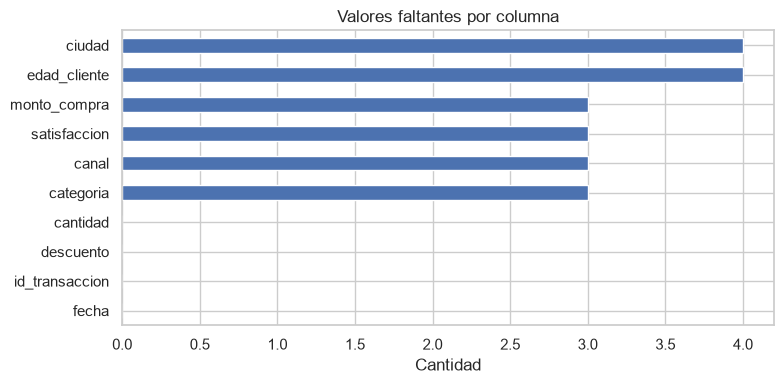

In [11]:
reporte_faltantes = pd.DataFrame({
    "cantidad": df.isna().sum(),
    "porcentaje": 100 * df.isna().mean()
}).sort_values("porcentaje", ascending=False)
display(reporte_faltantes)

reporte_faltantes["cantidad"].sort_values().plot(
    kind="barh", figsize=(8,4), title="Valores faltantes por columna"
)
plt.xlabel("Cantidad")
plt.tight_layout()
plt.show()

### 4.2 Duplicados y valores únicos

In [12]:
print("Duplicados exactos:", df.duplicated().sum())
display(df[df.duplicated(keep=False)])
for col in ["ciudad", "canal", "categoria"]:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False))

Duplicados exactos: 1


,id_transaccion,fecha,edad_cliente,ciudad,canal,categoria,cantidad,monto_compra,descuento,satisfaccion
25,T0026,26/01/2025,33.0,Medellín,App,Tecnología,5,13978.91,0.15,4.2
180,T0026,26/01/2025,33.0,Medellín,App,Tecnología,5,13978.91,0.15,4.2



ciudad
ciudad
Bogotá          39
Medellín        32
MEDELLÍN        32
 bogotá         28
Cali            23
Barranquilla    23
NaN              4
Name: count, dtype: int64

canal
canal
 WEB      36
TIENDA    33
app       32
Tienda    26
Web       26
App       25
NaN        3
Name: count, dtype: int64

categoria
categoria
Tecnología     44
tecnología     37
HOGAR          31
Alimentos      25
Ropa           21
Hogar          20
NaN             3
Name: count, dtype: int64


### Actividad 2
Construye una tabla con: `problema`, `columna`, `evidencia`, `riesgo` y `acción propuesta`. Incluye faltantes, duplicados, etiquetas inconsistentes y valores sospechosos. Un valor extremo no siempre es un error.

| Problema | Columna | Evidencia | Riesgo | Acción propuesta |
| :--- | :--- | :--- | :--- | :--- |
| **Valores Faltantes, es decir celdas las cuales les hace falta determinarse** | `ciudad`, `edad_cliente`, `monto_compra`, `satisfaccion`, `canal`, `categoria` | Entre 3 y 4 nulos (1.6% - 2.2% del total) | Pérdida de datos en agrupamientos y sesgo en métricas | Imputar numéricos con mediana, categóricos con moda/‘Desconocido’ o eliminar fila si son pocos datos |
| **Registros Duplicados, mas de uno que contengan los mismos datos** | `id_transaccion` | 1 fila totalmente duplicada (transacción T0026) | Sobreconteo de ventas e ingresos totales (puede volver a tener en cuenta este valor) | Eliminar la fila duplicada conservando una (`df.drop_duplicates()`) |
| **Etiquetas Inconsistentes, mayusculas, comas y minusculas** | `ciudad`, `canal`, `categoria` | Distintas escrituras (ej. Bogotá/bogotá, WEB/Web) | Fragmentación de métricas al agrupar categorías | Estandarizar a minúsculas y quitar espacios (`.str.lower().str.strip()`) |
| **Valores Atípicos / Incoherentes** | `edad_cliente` | Edad máxima registrada de 250 años | Sesgo severo en el promedio de edad | Imputar con la mediana o filtrar edades improbables o insostenibles (`> 100`) |
| **Valores Negativos Inválidos** | `monto_compra` | Monto mínimo registrado de -1500.0 | Distorsión en los ingresos y totales financieros, no representa un valor valido | Eliminar el registro o corregir el signo si fue error tipográfico o de otro estilo |
| **Valores Fuera de Escala establecida** | `satisfaccion`, `descuento` | Satisfacción de 8.5 (escala 1-5) y descuento de 1.7 (170%) | Métricas e indicadores fuera de rango real | Limitar/recortar a la escala máxima permitida (5.0 y 1.0) |

## 5. Limpieza reproducible

Crea una copia de trabajo y registra cuántas filas cambian en cada paso.

In [15]:
df_original = df.copy(deep=True)
limpio = df.copy(deep=True)

# Eliminar únicamente duplicados exactos para este ejercicio
n_antes = len(limpio)
limpio = limpio.drop_duplicates()
print("Duplicados eliminados:", n_antes - len(limpio))

Duplicados eliminados: 1


### 5.1 Convertir tipos y revisar fechas inválidas

`errors="coerce"` convierte fechas no interpretables en `NaT`, para poder identificarlas explícitamente.

In [16]:
limpio["fecha"] = pd.to_datetime(
    limpio["fecha"], format="%d/%m/%Y", errors="coerce"
)
sin_fecha = limpio[limpio["fecha"].isna()].copy()
print("Fechas inválidas:", len(sin_fecha))
display(sin_fecha)
# Separar para revisión, no borrar sin evidencia
limpio = limpio[limpio["fecha"].notna()].copy()

Fechas inválidas: 1


,id_transaccion,fecha,edad_cliente,ciudad,canal,categoria,cantidad,monto_compra,descuento,satisfaccion
35,T0036,NaT,49.0,bogotá,TIENDA,Alimentos,3,13797.68,0.25,3.9


### 5.2 Normalizar etiquetas de texto

Quitar espacios y uniformar mayúsculas/minúsculas ayuda a unificar categorías. Esto es **normalización de texto**, no normalización estadística de variables numéricas.

In [18]:
for col in ["ciudad", "canal", "categoria"]:
    limpio[col] = limpio[col].astype("string").str.strip().str.lower()

limpio["ciudad"] = limpio["ciudad"].replace({
    "bogotá": "Bogotá", "medellín": "Medellín",
    "cali": "Cali", "barranquilla": "Barranquilla"
})
limpio["canal"] = limpio["canal"].replace({
    "web": "Web", "tienda": "Tienda", "app": "App"
})
limpio["categoria"] = limpio["categoria"].replace({
    "tecnología": "Tecnología", "hogar": "Hogar",
    "ropa": "Ropa", "alimentos": "Alimentos"
})
for col in ["ciudad", "canal", "categoria"]:
    print(col, limpio[col].value_counts(dropna=False).to_dict())

ciudad {'Bogotá': 66, 'Medellín': 63, 'Cali': 23, 'Barranquilla': 23, <NA>: 4}
canal {'Web': 62, 'Tienda': 58, 'App': 56, <NA>: 3}
categoria {'Tecnología': 80, 'Hogar': 51, 'Alimentos': 24, 'Ropa': 21, <NA>: 3}


### 5.3 Identificar valores fuera de reglas

Reglas didácticas: edad entre 18 y 100; cantidad mayor que cero; monto no negativo; descuento entre 0 y 1; satisfacción entre 1 y 5.

In [19]:
reglas = {
    "edad_cliente": (18, 100),
    "cantidad": (1, 1000),
    "monto_compra": (0, None),
    "descuento": (0, 1),
    "satisfaccion": (1, 5)
}
for col, (minimo, maximo) in reglas.items():
    fuera = pd.Series(False, index=limpio.index)
    if minimo is not None:
        fuera |= limpio[col].notna() & (limpio[col] < minimo)
    if maximo is not None:
        fuera |= limpio[col].notna() & (limpio[col] > maximo)
    print(f"{col}: {fuera.sum()} valores fuera de rango")
    display(limpio.loc[fuera, ["id_transaccion", col]].head(10))

edad_cliente: 1 valores fuera de rango


,id_transaccion,edad_cliente
12,T0013,250.0


cantidad: 1 valores fuera de rango


,id_transaccion,cantidad
61,T0062,0


monto_compra: 1 valores fuera de rango


,id_transaccion,monto_compra
45,T0046,-1500.0


descuento: 1 valores fuera de rango


,id_transaccion,descuento
77,T0078,1.7


satisfaccion: 1 valores fuera de rango


,id_transaccion,satisfaccion
102,T0103,8.5


### 5.4 Tratar inválidos y faltantes

Para este ejercicio, los valores fuera de rango se marcan como faltantes. Luego se imputa la mediana para variables numéricas y la moda para variables categóricas. Esta no es una regla universal: documenta y justifica cada decisión.

In [20]:
limpio.loc[~limpio["edad_cliente"].between(18,100), "edad_cliente"] = np.nan
limpio.loc[limpio["monto_compra"] < 0, "monto_compra"] = np.nan
limpio.loc[~limpio["descuento"].between(0,1), "descuento"] = np.nan
limpio.loc[limpio["cantidad"] < 1, "cantidad"] = np.nan
limpio.loc[~limpio["satisfaccion"].between(1,5), "satisfaccion"] = np.nan

numericas = ["edad_cliente", "cantidad", "monto_compra", "descuento", "satisfaccion"]
categoricas = ["ciudad", "canal", "categoria"]
for col in numericas:
    limpio[col] = limpio[col].fillna(limpio[col].median())
for col in categoricas:
    moda = limpio[col].mode(dropna=True)
    if not moda.empty:
        limpio[col] = limpio[col].fillna(moda.iloc[0])

display(limpio.isna().sum().to_frame("faltantes finales"))

,faltantes finales
id_transaccion,0
fecha,0
edad_cliente,0
ciudad,0
canal,0
categoria,0
cantidad,0
monto_compra,0
descuento,0
satisfaccion,0


**Nota profesional:** conserva un reporte de las filas rechazadas o corregidas. En Machine Learning, los parámetros de imputación deben ajustarse solo con entrenamiento para evitar fuga de información.

## 6. Análisis univariado

### 6.1 Estadísticas descriptivas

In [21]:
display(limpio[numericas].describe().T)

,count,mean,std,min,25%,50%,75%,max
edad_cliente,179.0,36.424581,9.289880,18.00,30.000,36.00,42.0,69.00
cantidad,179.0,3.530726,1.643135,1.00,2.000,4.00,5.0,6.00
monto_compra,179.0,27092.003743,16058.989512,5939.56,16030.735,22514.13,32847.5,98926.30
descuento,179.0,0.112291,0.088304,0.00,0.050,0.10,0.2,0.25
satisfaccion,179.0,3.941341,0.733983,1.10,3.500,4.00,4.4,5.00


### 6.2 Histogramas para variables numéricas

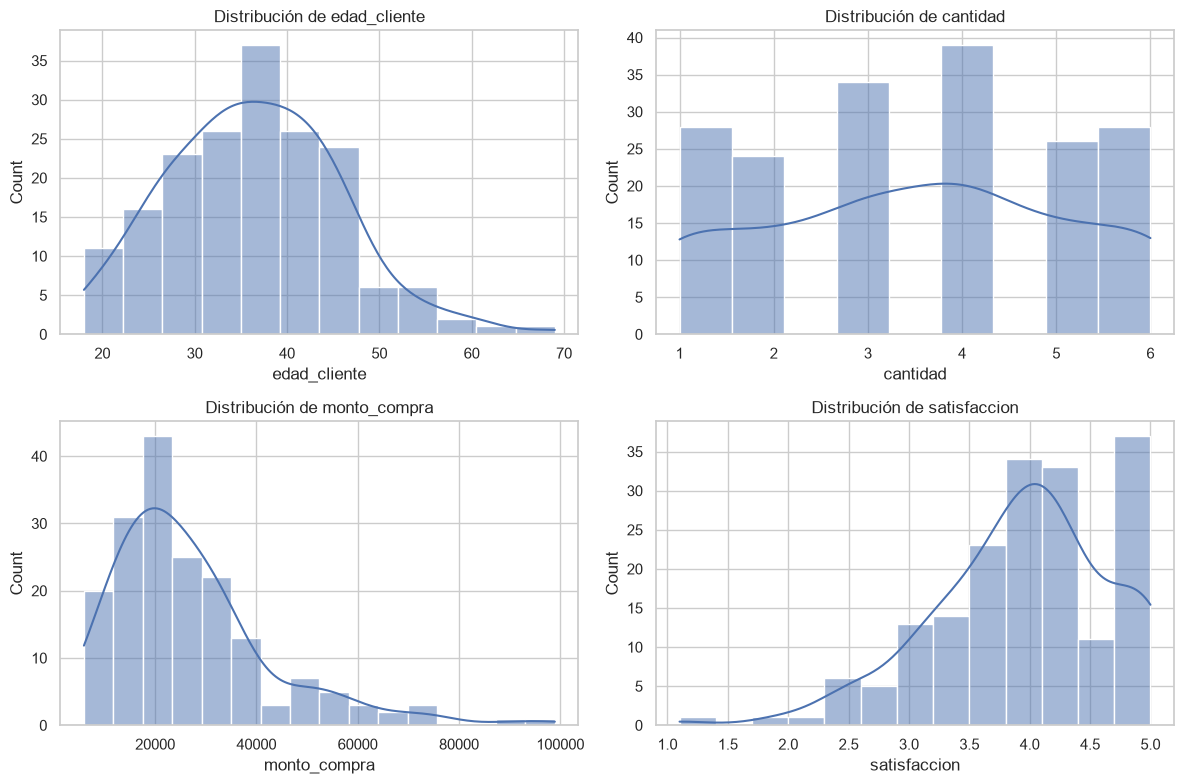

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(12,8))
for ax, col in zip(axes.flat, ["edad_cliente", "cantidad", "monto_compra", "satisfaccion"]):
    sns.histplot(data=limpio, x=col, kde=True, ax=ax)
    ax.set_title(f"Distribución de {col}")
plt.tight_layout()
plt.show()

### 6.3 Frecuencias de variables categóricas

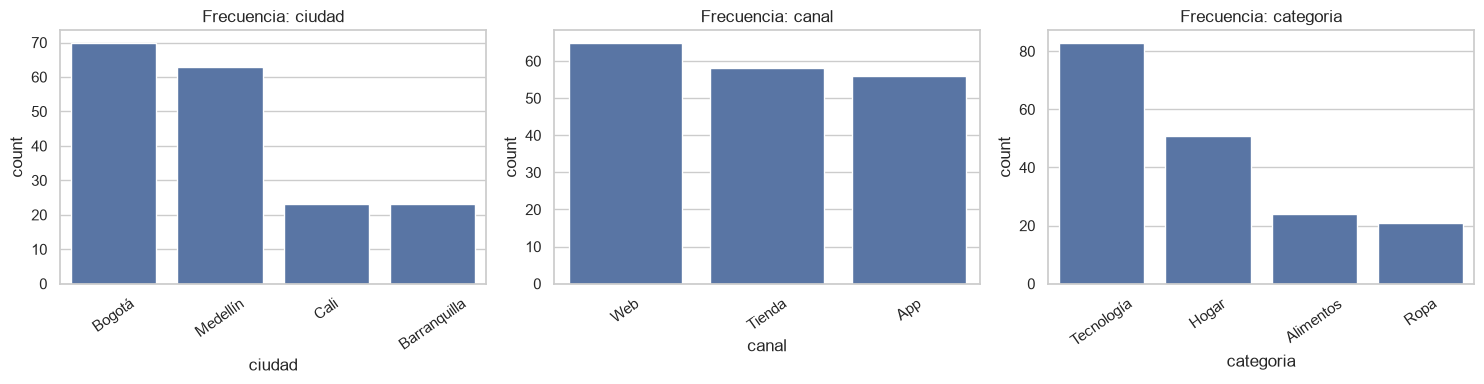

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, col in zip(axes, categoricas):
    sns.countplot(data=limpio, x=col, order=limpio[col].value_counts().index, ax=ax)
    ax.set_title(f"Frecuencia: {col}")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

### Actividad 3
Describe dos patrones observados en las distribuciones y uno que te sorprenda. Diferencia claramente entre lo que muestra el gráfico y tu interpretación.

### Solución 
- patrón 1, Bogota es una ciudad con mayor volumen de transacciones y tecnologia siendo una de las categorias mas compradas
- según este analisis se puede deducir que bogota concentra mayor cantidad economica y base de clientes que otras ciudades como cali y barranquilla, mientras que los artículos tecnológicos son los de mayor rotación comercial en el canal digital y físico, es deicir la categoria de tecnologia es la que concentra la mayor cantidad de ventas
- patrón 2, Las frecuencias en la variable canal (Web, Tienda, App) muestran barras con niveles bastante similares y cercanas entre sí, sin un canal que acapare el 80% o 90% de las ventas, lo que quiere decir que no existen diferencias exageradas y se encuentran bien distribuidas entre las tres opciones.
- podriamos decir que segun esta información las empresas no son tan agresivas en cuanto a que los clientes tienen libertad en alternar en el tipo de compra, tanto en tienda fisica, en pagina web y movil
- patrón impactante, es sorprendente como la tecnologia es el elemento con una tasa muy alta, al contrario de elementos basicos y fundamentales como lo son Alimentos y ropa, teniendo una caida critica
- es un poco curioso como la tecnologia es un elemento mucho mas relevante por encima de elementos que son adquiridos todo el tiempo, esto me lleva a pensar que el dataset analiza un mercado un poco mas enfocado en la tecnologia dejando de segundo plano estas dos categorias

## 7. Valores atípicos (outliers)

El rango intercuartílico (IQR) marca candidatos por debajo de Q1 − 1.5 × IQR o por encima de Q3 + 1.5 × IQR. Es una señal para investigar, no una instrucción automática de eliminar.

Q1=16030.74; Q3=32847.50; IQR=16816.76
Límites: -9194.41 a 58072.65
Candidatos: 10


,id_transaccion,monto_compra,categoria,canal
31,T0032,74554.85,Ropa,Web
63,T0064,73021.78,Tecnología,Tienda
67,T0068,59048.47,Tecnología,App
70,T0071,66284.70,Tecnología,Tienda
108,T0109,59042.65,Hogar,Web
109,T0110,98926.30,Tecnología,Web
120,T0121,75280.52,Tecnología,Web
128,T0129,67258.84,Hogar,Web
130,T0131,60921.30,Hogar,Web
154,T0155,90258.34,Tecnología,Web


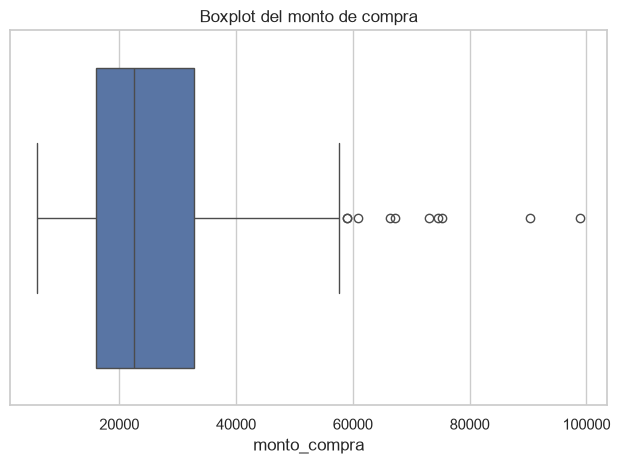

In [24]:
col = "monto_compra"
q1, q3 = limpio[col].quantile([.25, .75])
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5*iqr, q3 + 1.5*iqr
candidatos = limpio[(limpio[col] < lim_inf) | (limpio[col] > lim_sup)]
print(f"Q1={q1:.2f}; Q3={q3:.2f}; IQR={iqr:.2f}")
print(f"Límites: {lim_inf:.2f} a {lim_sup:.2f}")
print("Candidatos:", len(candidatos))
display(candidatos[["id_transaccion", "monto_compra", "categoria", "canal"]].head(15))

sns.boxplot(data=limpio, x="monto_compra")
plt.title("Boxplot del monto de compra")
plt.tight_layout()
plt.show()

**Preguntas:** ¿qué diferencia hay entre un dato inválido y un outlier? ¿Por qué no deben eliminarse automáticamente las compras altas? ¿Qué información adicional pedirías al área de negocio?

## Solución

- Dato invalido: es un error que en la vida real representa algo imposible, como ejemplo tenemos que en el dataset que ponia un limite una edad de 250 años lo cual no tiene logica y debe corregirse 
- outlier: puede llegar a ser un numero de un valor muy extremo, a pesar de ser alto es completamente legitimo dentro de un negocio por lo que no es un error
- no se pueden eliminar las compras altas ya que representan a los compradores mas fieles que se mantienen en una compra constante, si se eliminaran se perderia informacion de estudio relevante acerca de sus ingresos reales y el estudio de sus mejores clientes
- Se podría pedir el perfil o tipo de cliente que realizó la transacción (si es una cuenta corporativa o un cliente frecuente), si la compra coincidió con una fecha especial de alta demanda (como el Black Friday o lanzamientos exclusivos), o si el canal de venta incluyó algún paquete especial de servicios.

## 8. Análisis bivariado

### 8.1 Cantidad y monto

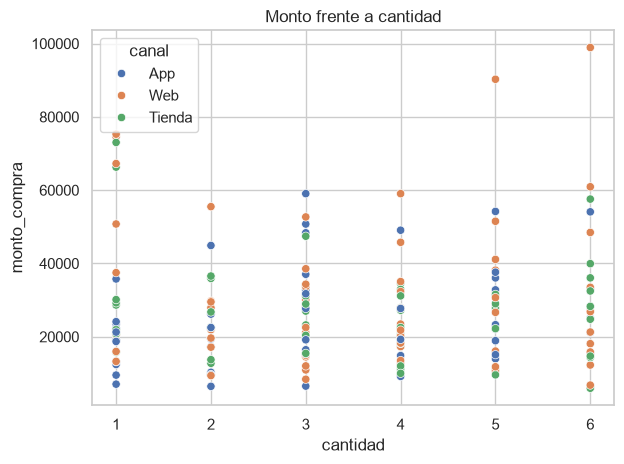

In [25]:
sns.scatterplot(data=limpio, x="cantidad", y="monto_compra", hue="canal")
plt.title("Monto frente a cantidad")
plt.tight_layout()
plt.show()

### 8.2 Monto por categoría y canal

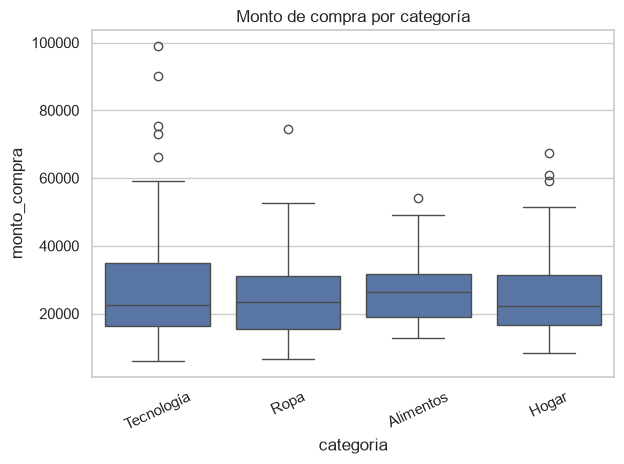

,canal,monto_promedio,transacciones
0,App,24803.638036,56
1,Tienda,25472.034310,58
2,Web,30509.030000,65


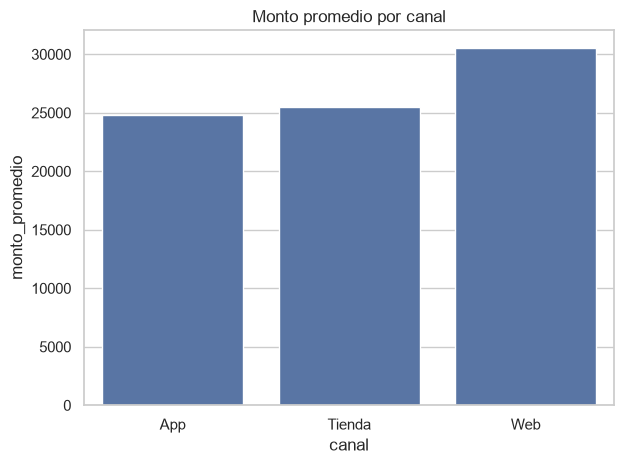

In [26]:
sns.boxplot(data=limpio, x="categoria", y="monto_compra")
plt.title("Monto de compra por categoría")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

resumen_canal = limpio.groupby("canal", as_index=False).agg(
    monto_promedio=("monto_compra", "mean"),
    transacciones=("id_transaccion", "count")
)
display(resumen_canal)
sns.barplot(data=resumen_canal, x="canal", y="monto_promedio")
plt.title("Monto promedio por canal")
plt.tight_layout()
plt.show()

### 8.3 Correlaciones numéricas

La correlación de Pearson mide relación lineal, no causalidad, y puede no capturar relaciones no lineales.

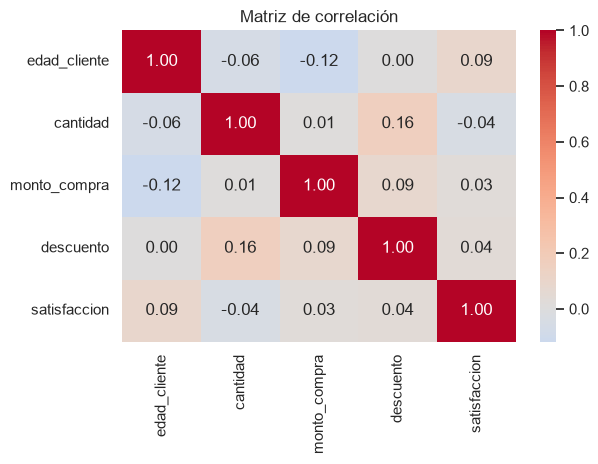

,edad_cliente,cantidad,monto_compra,descuento,satisfaccion
edad_cliente,1.000000,-0.056434,-0.118361,0.004218,0.089937
cantidad,-0.056434,1.000000,0.011768,0.163876,-0.037859
monto_compra,-0.118361,0.011768,1.000000,0.086374,0.032190
descuento,0.004218,0.163876,0.086374,1.000000,0.035456
satisfaccion,0.089937,-0.037859,0.032190,0.035456,1.000000


In [27]:
corr = limpio[numericas].corr(numeric_only=True)
sns.heatmap(corr, annot=True, cmap="coolwarm", center=0, fmt=".2f")
plt.title("Matriz de correlación")
plt.tight_layout()
plt.show()
display(corr)

### Actividad 4
Escribe tres hallazgos respaldados por gráficos o tablas. Para cada uno incluye evidencia, interpretación, limitación y una pregunta de seguimiento. No afirmes causalidad solo por observar correlación.

## Solución

- Hallazgo 1: El mercado web lidera por encima de los demas metodos de compra. La tabla de resumen y el gráfico de barras del punto 8.2 (Monto promedio por canal) muestran que el canal Web registra el mayor monto promedio de compra (~30,509), superando a Tienda (~25,472) y App (~24,803), a pesar de mantener volúmenes de transacciones cercanos (65, 58 y 56 respectivamente).
Los usuarios interactuan de forma mas voluminosa y costosa en las paginas web, con carros mas grandes que en las categorias de compras presenciales, a pesar de todo el promedio se puede ver afectado o sesgado por transacciones muy altas en las paginas web
- pregunta de seguimiento: ¿Qué categorías de productos específicos son las que impulsan este mayor promedio en la web frente a la aplicación móvil? (la cual tambien comparte la misma caracteristica de ser virtual)
- Hallazgo 2: Independencia entre la edad y el monto de compra, en la matriz, especificamente el punto (8.3) arroja el coeficiente -0.12 entre la edad del cliente y el monto de compra, por lo que la relación es muy debil, inclusive nula, por lo que el volumen del dinero gastado no esta relacionado directamente con la edad, tanto compradores jovenes como mayores realizan compras de diversos valores economicos de foma similar, pero el sistema evalua por medio de un sistema lineal por lo que no descarta la existencia de valores no lineales
- pregunta de seguimiento: ¿Se observarían diferencias significativas si agrupamos a los clientes por rangos de edad (generaciones) en lugar de evaluar la variable de forma continua?
- Hallazgo 3:pequeña relación entre el porcentaje de descuento y el volumen de unidades compradas, La matriz de correlación muestra un coeficiente de 0.16 entre las variables descuento y cantidad, posicionándose como una de las asociaciones positivas más destacadas entre las variables numéricas analizadas. Existe una ligera tendencia a que los clientes adquieran una mayor cantidad de productos por transacción cuando se aplican porcentajes de descuento elevados, lo que sugiere que las rebajas motivan compras por mayor volumen.
Al tratarse de una correlación baja (0.16), el descuento por sí solo no explica ni garantiza el incremento en la cantidad de unidades compradas por los usuarios solo tiende a llamar la atención y muy de vez en cuando este enganche funciona.
- pregunta de seguimiento: ¿A partir de qué porcentaje mínimo de descuento se empieza a notar un aumento real en la cantidad de unidades que un cliente decide llevar?

In [29]:
import pandas as pd

# Tabla para el Hallazgo 1: Comparativa de Canales de Venta
hallazgo_1_tabla = limpio.groupby("canal", as_index=False).agg(
    monto_promedio=("monto_compra", "mean"),
    transacciones=("id_transaccion", "count")
).sort_values("monto_promedio", ascending=False)

print("--- TABLA RESPALDO HALLAZGO 1: Monto Promedio por Canal ---")
display(hallazgo_1_tabla)

# Tabla para el Hallazgo 2 y 3: Matriz de Correlación de Pearson
hallazgo_corr_tabla = limpio[["edad_cliente", "cantidad", "monto_compra", "descuento", "satisfaccion"]].corr()

print("\n--- TABLA RESPALDO HALLAZGO 2 Y 3: Matriz de Correlaciones ---")
display(hallazgo_corr_tabla)

--- TABLA RESPALDO HALLAZGO 1: Monto Promedio por Canal ---


,canal,monto_promedio,transacciones
2,Web,30509.030000,65
1,Tienda,25472.034310,58
0,App,24803.638036,56



--- TABLA RESPALDO HALLAZGO 2 Y 3: Matriz de Correlaciones ---


,edad_cliente,cantidad,monto_compra,descuento,satisfaccion
edad_cliente,1.000000,-0.056434,-0.118361,0.004218,0.089937
cantidad,-0.056434,1.000000,0.011768,0.163876,-0.037859
monto_compra,-0.118361,0.011768,1.000000,0.086374,0.032190
descuento,0.004218,0.163876,0.086374,1.000000,0.035456
satisfaccion,0.089937,-0.037859,0.032190,0.035456,1.000000


## 9. Normalización y estandarización

No son lo mismo que limpiar etiquetas de texto.

### Normalización Min-Max
Transforma una variable a un rango, normalmente [0, 1]:

`x_norm = (x - mínimo) / (máximo - mínimo)`

Es útil cuando se necesita una escala acotada, pero es sensible a valores extremos.

### Estandarización Z-score
Transforma los datos según su media y desviación estándar:

`z = (x - media) / desviación_estándar`

La media resultante suele estar cerca de 0 y la desviación estándar cerca de 1. Los valores no quedan acotados a un rango fijo.

In [30]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

variables_escalado = ["edad_cliente", "cantidad", "monto_compra"]
X = limpio[variables_escalado].copy()

mm = MinMaxScaler()
ss = StandardScaler()
X_mm = pd.DataFrame(mm.fit_transform(X), columns=[f"{c}_minmax" for c in X.columns], index=X.index)
X_ss = pd.DataFrame(ss.fit_transform(X), columns=[f"{c}_zscore" for c in X.columns], index=X.index)

display(pd.concat([X, X_mm, X_ss], axis=1).head())

,edad_cliente,cantidad,monto_compra,edad_cliente_minmax,cantidad_minmax,monto_compra_minmax,edad_cliente_zscore,cantidad_zscore,monto_compra_zscore
0,40.0,3.0,50750.74,0.431373,0.4,0.481909,0.385952,-0.323902,1.477372
1,26.0,2.0,21911.37,0.156863,0.2,0.171764,-1.125291,-0.934202,-0.323505
2,45.0,3.0,52685.83,0.529412,0.4,0.502720,0.925682,-0.323902,1.598209
3,47.0,1.0,19084.00,0.568627,0.0,0.141358,1.141574,-1.544502,-0.500061
4,36.0,5.0,54191.27,0.352941,0.8,0.518910,-0.045832,0.896697,1.692216


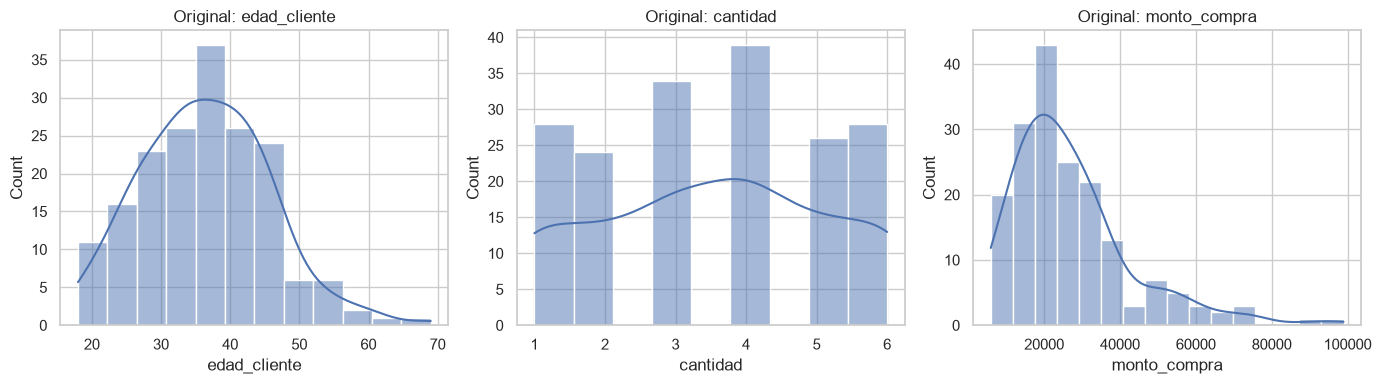

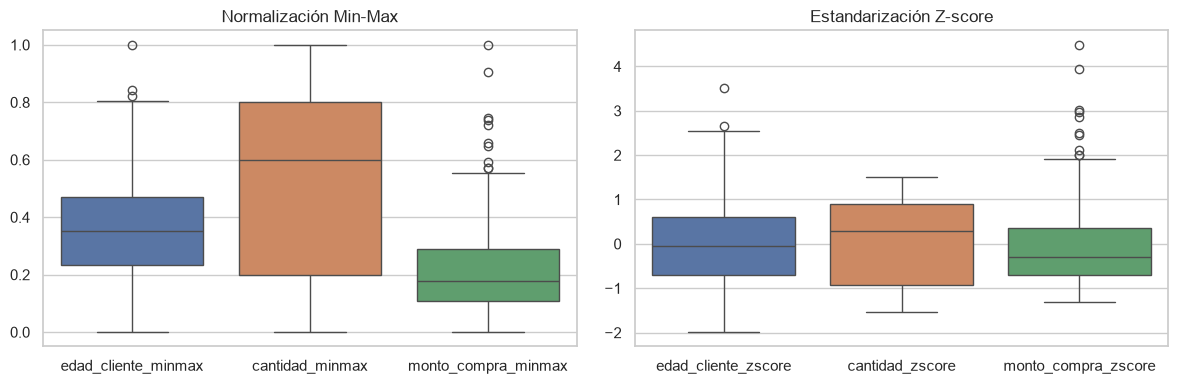

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(14,4))
for ax, col in zip(axes, variables_escalado):
    sns.histplot(X[col], kde=True, ax=ax)
    ax.set_title(f"Original: {col}")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.boxplot(data=X_mm, ax=axes[0])
axes[0].set_title("Normalización Min-Max")
sns.boxplot(data=X_ss, ax=axes[1])
axes[1].set_title("Estandarización Z-score")
plt.tight_layout()
plt.show()

### ¿Cuándo usar cada técnica?
- **Min-Max:** cuando se requiere un rango acotado, por ejemplo, en ciertos modelos basados en distancias o redes neuronales.
- **Z-score:** cuando interesa escalar por media y variabilidad, por ejemplo, en regresión regularizada o SVM.
- **Modelos de árboles:** normalmente no necesitan escalar las variables numéricas.

**Regla para IA:** separa entrenamiento y prueba antes de ajustar escaladores. Usa `fit` solo con entrenamiento y `transform` en prueba. Ajustar el escalador con todo el dataset puede producir fuga de información.

In [32]:
from sklearn.model_selection import train_test_split
X = limpio[["edad_cliente", "cantidad", "monto_compra", "descuento"]]
y = (limpio["satisfaccion"] >= 4).astype(int)  # Etiqueta ilustrativa

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
escalador = StandardScaler()
X_train_scaled = escalador.fit_transform(X_train)
X_test_scaled = escalador.transform(X_test)
print("Train:", X_train_scaled.shape, "| Test:", X_test_scaled.shape)

Train: (143, 4) | Test: (36, 4)


## 10. Validación y exportación

In [ ]:
print("Dimensiones fuente:", df_original.shape)
print("Dimensiones limpias:", limpio.shape)
display(limpio.isna().sum().to_frame("faltantes"))
limpio.to_csv("transacciones_limpias.csv", index=False, encoding="utf-8-sig")
sin_fecha.to_csv("transacciones_revision_fecha.csv", index=False, encoding="utf-8-sig")
print("Se exportaron los datos limpios y los registros con fecha inválida.")

## 11. Entregables

Entrega el notebook ejecutado, el CSV limpio, el archivo de registros enviados a revisión y una conclusión escrita.

1. Diagnóstico de calidad antes de limpiar.
2. Limpieza reproducible y justificada.
3. Tres gráficos univariados y tres bivariados, cada uno con interpretación.
4. Análisis de outliers y decisión argumentada.
5. Comparación de variables originales, normalizadas y estandarizadas.
6. Tres hallazgos, dos limitaciones y recomendaciones.

### Preguntas de cierre
- ¿Qué diferencia hay entre EDA, limpieza y transformación?
- ¿Por qué conservar el dataset original?
- ¿Qué decisiones dependen del negocio?
- ¿Qué transformaciones pueden generar fuga de información?
- ¿Qué parte automatizarías primero y cómo registrarías su ejecución?

### Rúbrica sugerida
| Criterio | Peso |
|---|---:|
| Inspección y diagnóstico | 15 % |
| Limpieza y justificación | 25 % |
| Gráficos e interpretación | 20 % |
| Normalización y estandarización | 15 % |
| Reproducibilidad y documentación | 15 % |
| Conclusiones y limitaciones | 10 % |
| **Total** | **100 %** |

### Buenas prácticas
Conserva la fuente original; documenta reglas; no elimines outliers automáticamente; registra filas rechazadas; utiliza funciones reutilizables; separa exploración y transformación; evita fuga de información; interpreta los gráficos dentro del contexto del problema.

**Conclusión:** EDA no es una colección de gráficos. Es un proceso sistemático para comprender la información, evaluar su calidad y tomar decisiones fundamentadas antes de construir productos analíticos o modelos de IA.

In [33]:
limpio.to_csv("transacciones_limpias.csv", index=False)
sin_fecha.to_csv("registros_en_revision.csv", index=False)
print("¡Archivos generados con éxito :D!")

¡Archivos generados con éxito :D!
